# Sentiment Analysis

A transformer classifier trained from scratch in PyTorch to classify IMDB movie reviews as positive (1) or negative (0). The project uses the bert-base-uncased tokenizer and a custom transformer model.

The workflow covers data preparation, tokenization, model construction, training, and evaluation.

## Load the Dataset

Extract the IMDB review archive before loading the labeled training and test reviews. The archive must be available at the path used below.

In [3]:
import os
import pandas as pd

In [4]:
# Unpack the dataset - uncomment the line below to run
!tar -xzf aclImdb_v1.tar.gz

### Dataset Paths

Paths to the positive and negative review folders for each split.

In [5]:
# Define paths to dataset
train_pos_path = 'aclImdb/train/pos' # Path to the directory containing positive reviews from the training set
train_neg_path = 'aclImdb/train/neg' # Path to the directory containing negative reviews from the training set
test_pos_path = 'aclImdb/test/pos' # Path to the directory containing positive reviews from the test set
test_neg_path = 'aclImdb/test/neg' # Path to the directory containing negative reviews from the test set

### Read Review Files

Load review text from the dataset folders.

In [6]:
def load_dataset(folder):
    """
    Reads all text files in the specified folder and returns their content as a list.

    Args:
        folder (str): Path to the folder containing text files.

    Returns:
        list: A list of strings, where each string is the content of a text file.
    """
    #TODO: Implement the function here
    data = []
    for name in os.listdir(folder) :
        if name.endswith(".txt"):
         file_path = os.path.join(folder , name)
         
         with open (file_path , "r" , encoding="utf-8") as file:
            data.append(file.read())
    return data       

Load positive and negative reviews for training and testing.

In [7]:
# Load training and testing data
train_pos = load_dataset(train_pos_path)
train_neg = load_dataset(train_neg_path)
test_pos = load_dataset(test_pos_path)
test_neg = load_dataset(test_neg_path)

Combine review text and sentiment labels into pandas DataFrames.

In [8]:
# Create DataFrames
train_df = pd.DataFrame({
    'review': train_pos + train_neg,
    'label': [1] * len(train_pos) + [0] * len(train_neg)
})

test_df = pd.DataFrame({
    'review': test_pos + test_neg,
    'label': [1] * len(test_pos) + [0] * len(test_neg)
})

print(train_df.head())

                                              review  label
0  Silly, hilarious, tragic, sad, inevitable.<br ...      1
1  I actually like the original, and this film ha...      1
2  For my humanities quarter project for school, ...      1
3  To me this was more a wake up call, and realiz...      1
4  This movie is a lot of fun. What makes it grea...      1


Check that the loaded datasets have the expected sizes.

In [9]:
# Assert that both datasets have the expected number of rows
assert train_df.shape[0] == 25000, "Training dataset does not have 25000 rows."
assert test_df.shape[0] == 25000, "Testing dataset does not have 25000 rows."

# Assert that both datasets have exactly two columns
assert train_df.shape[1] == 2, "Training dataset does not have exactly 2 columns."
assert test_df.shape[1] == 2, "Testing dataset does not have exactly 2 columns."


### Explore the Dataset

Inspect dataset structure, label balance, and review lengths.

In [10]:
train_df.info()
train_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB


,label
count,25000.00000
mean,0.50000
std,0.50001
min,0.00000
25%,0.00000
50%,0.50000
75%,1.00000
max,1.00000


<Axes: xlabel='label'>

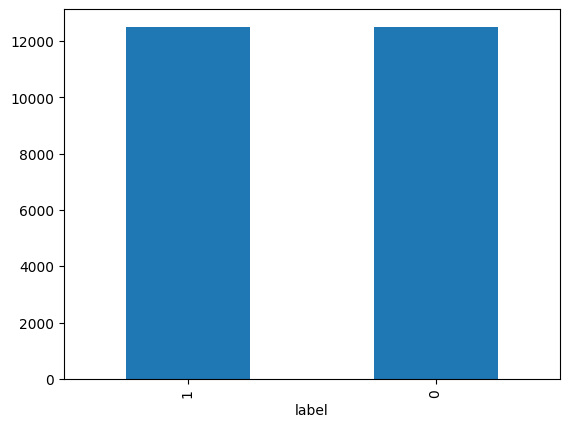

In [11]:
train_df['label'].value_counts().plot(kind="bar")


<Axes: ylabel='Frequency'>

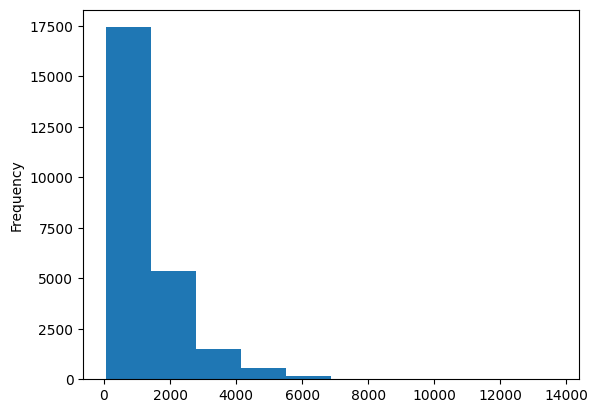

In [12]:
train_df['review'].str.len().plot(kind="hist")

In [13]:

train_df[train_df['label']==1].head()

,review,label
0,"Silly, hilarious, tragic, sad, inevitable.<br ...",1
1,"I actually like the original, and this film ha...",1
2,"For my humanities quarter project for school, ...",1
3,"To me this was more a wake up call, and realiz...",1
4,This movie is a lot of fun. What makes it grea...,1


In [14]:
train_df[train_df['label']==0].head()

,review,label
12500,"Ah yez, the Sci Fi Channel produces Yeti anoth...",0
12501,"Dumb is as dumb does, in this thoroughly unint...",0
12502,I understand what this movie was trying to por...,0
12503,A friend told me of John Fante last summer aft...,0
12504,"From the critical acclaim, I expected more fro...",0


### Training and Validation Split

Shuffle the labeled training data before creating training and validation subsets.

In [15]:
# Split train data into training and validation sets manually
train_size = int(0.9 * len(train_df))
# Shuffle the dataset
shuffled_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
train_data = shuffled_df.iloc[:train_size]
val_data = shuffled_df.iloc[train_size:]

### Tokenization

Use the pretrained bert-base-uncased tokenizer to convert review text into token IDs. The classifier itself is trained from scratch.

In [16]:
from transformers import AutoTokenizer

# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

/opt/conda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/conda/lib/python3.10/site-packages/huggingface_hub/file_download.py:795: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Preview tokenization on sample reviews.

In [17]:
# Take sample inputs from the dataset
sample_texts = train_data['review'].sample(3, random_state=42).tolist()

# Tokenize sample inputs
tokenized_samples = tokenizer(sample_texts, truncation=True, padding="max_length", max_length=128, return_tensors="pt")

In [18]:
print(tokenized_samples)

{'input_ids': tensor([[  101,  1996, 10828,  2006,  2029,  2023,  3185,  2003,  2241,  3464,
          2028,  1997,  1996,  2087,  2540,  1011, 14916,  4667,  2808,  1045,
          2031,  2412,  3191,  1012,  2009,  4136,  1996,  6429,  3441,  1997,
          2048,  5208,  1010,  2119,  2040,  3687, 13347,  1998,  4847,  2551,
          2092,  2046,  2037,  3963,  1005,  1055,  2004,  1037,  3836,  1998,
          1037, 24385,  1010,  2059,  2973,  2178,  2382,  2086,  2007, 13372,
          1012, 10090,  9266, 15539,  1996,  2143,  2007,  2014,  6669, 16371,
          6651,  2094,  2836,  2004,  1996, 22614,  1000,  2304,  2121,  1000,
         29298,  1010,  1996, 24385,  1012,  2016,  2025,  2069, 16783,  2014,
          4963,  1010, 17076,  3367,  1010,  1998,  9866,  2092,  1025,  2016,
         11082,  2017,  2113,  3599,  2073,  2027,  1005,  2310,  2272,  2013,
          2478,  2019,  4610,  1997,  2616,  1012, 22939,  7295,  2078, 10767,
          2038,  1996,  2514,  1997,  

Inputs are truncated to a maximum of 128 tokens and returned as PyTorch tensors. Padding allows sequences to be batched.

## Dataset and Data Loaders

The custom IMDBDataset class returns tokenized reviews and their sentiment labels.

In [19]:
import torch
from torch.utils.data import Dataset
MAX_LENGTH = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


Use a maximum input length of 128 tokens.

In [20]:
from torch.utils.data import Dataset

class IMDBDataset(Dataset):
    """
    A custom PyTorch Dataset for the IMDB dataset.

    This class preprocesses text data using a tokenizer and returns tokenized inputs
    along with their corresponding labels for sentiment analysis.

    Attributes:
        data (pd.DataFrame): A DataFrame containing text and label columns.
        tokenizer (transformers.PreTrainedTokenizer): The tokenizer used for preprocessing text.
        max_length (int): Maximum length for tokenized sequences.
    """
    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        self.data= data
        self.tokenizer = tokenizer
        self.max_length = max_length
        

    def __len__(self):
        return len(self.data)
        
    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = row['review']
        label = row['label']
        tokenized_text =self.tokenizer(
            text
           ,truncation = True
           ,max_length=self.max_length
           ,padding = 'max_length'
           ,return_tensors = 'pt' )
        
        return tokenized_text['input_ids'].squeeze(0) , label
        #TODO: Write code for the __getitem__() function

### Initialize Datasets

Create datasets from the prepared DataFrames.

In [21]:
# Initialize the datasets
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)

### Create Data Loaders

Prepare batches for model training and evaluation.

In [22]:
from torch.utils.data import DataLoader

# Define batch size
BATCH_SIZE = 32

# Create DataLoader instances
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

The training loader shuffles reviews each epoch. The following checks validate the dataset and batch structure.

In [23]:
assert len(train_dataset) == 22500, "Train dataset length mismatch!"
assert len(val_dataset) == 2500, "Validation dataset length mismatch!"
assert len(test_dataset) == 25000, "Test dataset length mismatch!"

import numpy as np

# Check the first item in the train dataset
input_ids, label = train_dataset[0]
assert isinstance(input_ids, torch.Tensor), "Input IDs should be a torch.Tensor!"
assert isinstance(label, (int, np.integer)), "Label should be an integer or int-like!"

# Ensure the input IDs tensor has the correct shape
assert input_ids.shape[0] == train_dataset.max_length, "Input IDs tensor has incorrect length!"

## Transformer Architecture

### Configuration

Define the vocabulary size, embedding dimensions, attention heads, transformer layers, and classification settings.

In [24]:
config = {
    "vocabulary_size": tokenizer.vocab_size,  # e.g., ~30522 for bert-base-uncased
    "num_classes": 2,                         # binary classification (pos/neg)
    "d_embed": 128,
    "context_size": MAX_LENGTH,
    "layers_num": 4,
    "heads_num": 4,
    "head_size": 32,  # 4 heads * 32 = 128 -> matches d_embed
    "dropout_rate": 0.1,
    "use_bias": True
}

The configuration controls the model dimensions, sequence length, dropout, and two-class output.

### Attention Head

Compute attention over token representations.

In [25]:
import torch.nn as nn
import math

class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Q_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.K_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.V_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])

        self.dropout = nn.Dropout(config["dropout_rate"])

        casual_attention_mask = torch.tril(torch.ones(config["context_size"], config["context_size"]))
        self.register_buffer('casual_attention_mask', casual_attention_mask)

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape
        Q = self.Q_weights(input)  # (B, T, head_size)
        K = self.K_weights(input)  # (B, T, head_size)
        V = self.V_weights(input)  # (B, T, head_size)

        # Q @ K^T => (B, T, T)
        attention_scores = Q @ K.transpose(1, 2)

        # Casual Mask
        attention_scores = attention_scores.masked_fill(
            self.casual_attention_mask[:tokens_num, :tokens_num] == 0,
            float('-inf')
        )
        attention_scores = attention_scores / math.sqrt(K.shape[-1])
        attention_scores = torch.softmax(attention_scores, dim=-1)
        attention_scores = self.dropout(attention_scores)

        return attention_scores @ V

Check the attention head using a batch of dummy embeddings.

In [26]:
# Instantiate the AttentionHead
attention_head = AttentionHead(config).to(device)

# Create a dummy input of shape (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
attention_output = attention_head(dummy_input)
print("AttentionHead output shape:", attention_output.shape)

AttentionHead output shape: torch.Size([32, 128, 32])


Expected attention-head output: (batch, sequence length, head size).

### Multi-Head Attention

In [27]:
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        heads_list = [AttentionHead(config) for _ in range(config["heads_num"])]
        self.heads = nn.ModuleList(heads_list)

        self.linear = nn.Linear(config["heads_num"] * config["head_size"], config["d_embed"])
        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, input):
        heads_outputs = [head(input) for head in self.heads]
        x = torch.cat(heads_outputs, dim=-1)  # (B, T, heads_num * head_size)
        x = self.linear(x)                   # (B, T, d_embed)
        x = self.dropout(x)
        return x

In [28]:
# Instantiate MultiHeadAttention
multi_head_attention = MultiHeadAttention(config).to(device)

# Same dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
mha_output = multi_head_attention(dummy_input)
print("MultiHeadAttention output shape:", mha_output.shape)

MultiHeadAttention output shape: torch.Size([32, 128, 128])


Expected output: (batch, sequence length, embedding dimension).

### Feed-Forward Network

In [29]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"]),
            nn.GELU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"]),
            nn.Dropout(config["dropout_rate"])
        )

    def forward(self, input):
        return self.linear_layers(input)

In [30]:
# Instantiate FeedForward
feed_forward = FeedForward(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
ff_output = feed_forward(dummy_input)
print("FeedForward output shape:", ff_output.shape)

FeedForward output shape: torch.Size([32, 128, 128])


Expected output: (batch, sequence length, embedding dimension).

### Transformer Block

In [31]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.multi_head = MultiHeadAttention(config)
        self.layer_norm_1 = nn.LayerNorm(config["d_embed"])

        self.feed_forward = FeedForward(config)
        self.layer_norm_2 = nn.LayerNorm(config["d_embed"])

    def forward(self, input):
        x = input
        x = x + self.multi_head(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

In [32]:
# Instantiate a single Block
block = Block(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
block_output = block(dummy_input)
print("Block output shape:", block_output.shape)

Block output shape: torch.Size([32, 128, 128])


Expected block output: (batch, sequence length, embedding dimension).

### Sentiment Classifier

DemoGPT combines token and positional embeddings with transformer blocks, mean pooling, and a two-class output layer.

In [33]:
class DemoGPT(nn.Module):
    def __init__(self, config):
        """
        Initialize the DemoGPT class with configuration parameters.

        Args:
        - config (dict): Configuration dictionary with the following keys:
            - "vocabulary_size": Size of the vocabulary.
            - "d_embed": Dimensionality of the embedding vectors.
            - "context_size": Maximum sequence length (context size).
            - "layers_num": Number of transformer layers.
            - "num_classes": Number of output classes (2 for binary classification).
        """
        super().__init__()
        # Token embedding layer: Maps token indices to embedding vectors.
        self.token_embedding_layer = nn.Embedding(config["vocabulary_size"], config["d_embed"])
        
        # Positional embedding layer: Adds positional information to the embeddings.
        self.positional_embedding_layer = nn.Embedding(config["context_size"], config["d_embed"])
        
        # Transformer layers: Stacked sequence of transformer blocks.
        blocks = [Block(config) for _ in range(config["layers_num"])]
        self.layers = nn.Sequential(*blocks)
        
        # Layer normalization: Applied to stabilize training.
        self.layer_norm = nn.LayerNorm(config["d_embed"])
        
        # TODO: Implement classification output layer - Maps pooled embeddings to class logits.
        self.classifier = nn.Linear(
            config["d_embed"] ,
            config ["num_classes"]
            
        )
    def forward(self, token_ids):
        """
        Forward pass of the model.

        Args:
        - token_ids (torch.Tensor): Input token indices of shape (B, T), 
                                    where B is the batch size, and T is the sequence length.
        
        Returns:
        - logits (torch.Tensor): Output logits of shape (B, num_classes).
        """
        batch_size, tokens_num = token_ids.shape

        # Step 1: Create embeddings for tokens and their positions
        x = self.token_embedding_layer(token_ids)  # Shape: (B, T, d_embed)
        positions = torch.arange(tokens_num, device=token_ids.device)  # Shape: (T,)
        pos_embed = self.positional_embedding_layer(positions)  # Shape: (T, d_embed)
        x = x + pos_embed.unsqueeze(0)  # Add positional embeddings to token embeddings
        
        # Step 2: Pass embeddings through transformer layers
        x = self.layers(x)  # Shape: (B, T, d_embed)
        x = self.layer_norm(x)  # Normalize across the feature dimension
        
        # Step 3: TODO: Apply mean pooling across the time dimension  # Shape: (B, d_embed)
        meanpool = x.mean(dim=1)
        # Step 4: TODO: Generate logits for classification  # Shape: (B, num_classes)
        logits =  self.classifier(meanpool)
        return logits

In [34]:
# Instantiate the model
demo_gpt = DemoGPT(config).to(device)

# Suppose we have a batch of size 32, each with a sequence length of 128
dummy_token_ids = torch.randint(
    0, config["vocabulary_size"], 
    (BATCH_SIZE, config["context_size"])
).to(device)

# Forward pass
logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)
print("Logits sample:\n", logits[:2])  # Print first two examples' logits

DemoGPT output shape: torch.Size([32, 2])
Logits sample:
 tensor([[-0.1619, -0.0420],
        [-0.1810, -0.0560]], device='cuda:0', grad_fn=<SliceBackward0>)


Expected classifier output: (batch size, 2), with one logit per sentiment class.

In [35]:
# Assert that the number of logits matches the number of classes
assert logits.size(1) == config["num_classes"], (
    f"Expected number of classes {config['num_classes']}, "
    f"but got {logits.size(1)}"
)

# Assert that the batch size of the output matches the input batch size
assert logits.size(0) == BATCH_SIZE, (
    f"Expected batch size {BATCH_SIZE}, "
    f"but got {logits.size(0)}"
)

## Accuracy Evaluation

Evaluate predictions without gradient calculation and report the percentage of correctly classified reviews.

In [42]:
def calculate_accuracy(model, data_loader, device):
    model.eval()
   
    total_correct = 0
    total_samples = 0
    with torch.no_grad():
        
        for batch in data_loader :
            input_ids = batch[0]
            labels = batch[1]

            input_ids = input_ids.to(device)
            labels = labels.to(device)
            logits = model(input_ids)
            prediction = torch.argmax(logits , dim=1)
        
            total_correct += (prediction == labels ).sum().item()
            total_samples += len(labels)
            
    accuracy = (total_correct / total_samples) * 100
    return accuracy

In [40]:
model = DemoGPT(config).to(device)

In [43]:
validation_accuracy = calculate_accuracy(model, val_loader, device)
print(f"Validation Accuracy: {validation_accuracy:.2f}%")

Validation Accuracy: 50.92%


The untrained model provides a baseline before optimization.

## Train the Model

Train for three epochs using cross-entropy loss and AdamW. Evaluate validation accuracy after each epoch.

In [44]:
import torch.optim as optim

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training parameters
EPOCHS = 3

# Initialize model, loss, and optimizer
model = DemoGPT(config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=3e-4)

# Training loop
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for step, (input_ids, labels) in enumerate(train_loader):
        # Move data to device
        input_ids = input_ids.to(device)
        labels = labels.to(device)

        # TODO: Implement forward pass
        logits = model (input_ids)
        # TODO: Calculate loss
        loss = criterion (logits , labels)
        # TODO: Set gradients to zero
        optimizer.zero_grad()
        # TODO: Backward pass
        loss.backward()
        # TODO: Step the optimizer
        optimizer.step()
        
        running_loss += loss.item()

        # Log training progress
        if (step + 1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{EPOCHS}], Step [{step+1}/{len(train_loader)}], "
                  f"Loss: {running_loss/100:.4f}")
            running_loss = 0.0

    # Evaluate validation accuracy
    val_accuracy = calculate_accuracy(model, val_loader, device)
    print(f"Epoch {epoch+1} - Validation Accuracy: {val_accuracy:.2f}%")

Epoch [1/3], Step [100/704], Loss: 0.6879
Epoch [1/3], Step [200/704], Loss: 0.6553
Epoch [1/3], Step [300/704], Loss: 0.6417
Epoch [1/3], Step [400/704], Loss: 0.6300
Epoch [1/3], Step [500/704], Loss: 0.5964
Epoch [1/3], Step [600/704], Loss: 0.5896
Epoch [1/3], Step [700/704], Loss: 0.5505
Epoch 1 - Validation Accuracy: 70.04%
Epoch [2/3], Step [100/704], Loss: 0.5222
Epoch [2/3], Step [200/704], Loss: 0.5266
Epoch [2/3], Step [300/704], Loss: 0.5069
Epoch [2/3], Step [400/704], Loss: 0.5056
Epoch [2/3], Step [500/704], Loss: 0.4971
Epoch [2/3], Step [600/704], Loss: 0.5072
Epoch [2/3], Step [700/704], Loss: 0.4766
Epoch 2 - Validation Accuracy: 74.68%
Epoch [3/3], Step [100/704], Loss: 0.4449
Epoch [3/3], Step [200/704], Loss: 0.4423
Epoch [3/3], Step [300/704], Loss: 0.4468
Epoch [3/3], Step [400/704], Loss: 0.4340
Epoch [3/3], Step [500/704], Loss: 0.4102
Epoch [3/3], Step [600/704], Loss: 0.4284
Epoch [3/3], Step [700/704], Loss: 0.4383
Epoch 3 - Validation Accuracy: 76.76%


Training loss is logged every 100 steps. Validation accuracy tracks performance on the held-out validation split.

## Test the Model

Evaluate the trained classifier on the test split.

In [46]:
# TODO: Calculate the accuracy of the model over the test set using the calculate_accuracy() function
testaccuracy = calculate_accuracy(model , test_loader , device) 
print(f" test Accuracy: {testaccuracy:.2f}%")

 test Accuracy: 76.61%


Compare test accuracy with the project target of 75%.

In [ ]:
import shutil
shutil.make_archive(
    "../Sen"

)

## Results and Conclusion

### Recorded Results

The original notebook reports the following results after three training epochs:

| Evaluation | Accuracy |
|---|---:|
| Before training (validation) | 50.92% |
| After training (validation) | 76.76% |
| After training (test) | 76.61% |

The recorded test accuracy exceeds the 75% project target. This experiment covers text preparation, tokenization, a custom transformer classifier, and model evaluation. Results may vary across runs.